# Atividade 5 — Análise global, local e de textura

**Unidade 3 | Capítulo 2**  
**Aluno:** Luiz Felipe Souza da Silva  
**Professor:** Rafael Carmo

## 1. Preparação do dataset e hipótese inicial

O objetivo é comparar três formas de representar as mesmas imagens: distribuição
de intensidades e cores, detalhes locais e textura. A comparação usa as figuras e
os valores calculados para observar o que cada descritor mostra sobre os objetos.

Reutilizei as 10 fotografias do mini dataset: cinco de um contrabaixo e cinco de uma
placa FPGA. Cada classe contém cinco capturas do mesmo objeto, em condições diferentes.

As fotos foram feitas com Galaxy S26, sob luz natural da janela do quarto, com variações
da cortina e da exposição da câmera. As distâncias aproximadas foram 40 cm para o
contrabaixo e 20 cm para a FPGA. Há mudanças de ângulo, enquadramento, face do objeto
e, na FPGA, condição antes/depois da limpeza. Nas atividades anteriores, o ruído foi
considerado visualmente baixo e não foi observado desfoque evidente. Sujeira e reflexos
foram considerados detalhes da cena.

O contrabaixo combina corpo preto, escudo claro, cordas e controles em um ambiente
com muitos elementos. A FPGA apresenta componentes e inscrições repetidos sobre a
placa azul, com fundo marrom. Espero que essas diferenças apareçam na cor e na
estrutura, mas o fundo e a exposição podem dificultar a comparação entre classes.

Minha hipótese inicial é que ORB será mais útil para comparar componentes, conectores,
cordas e controles. Os histogramas devem mostrar as diferenças de brilho e cor, e os
descritores de textura devem ajudar na comparação das superfícies.

```text
VC_iREDE/
├── dataset/
│   ├── originais/
│   │   ├── contrabaixo/  (contrabaixo_01.jpg a contrabaixo_05.jpg)
│   │   └── fpga/        (fpga_01.jpg a fpga_05.jpg)
│   └── derivadas/
│       ├── resolucao/  (versões de 20% da Atividade 1)
│       └── atividade_5/
├── notebooks/atividade_5.ipynb
├── tabelas/atividade_5/
└── metadata.csv
```

As bibliotecas são as anteriores mais `scikit-image`, usada em blobs, GLCM e LBP.
Caso falte, instale com `%pip install scikit-image` e reinicie o kernel. Execute as
células de cima para baixo. No Colab, a preparação pode clonar o repositório público;
para usar uma entrega ainda não publicada, envie e extraia o ZIP do projeto.

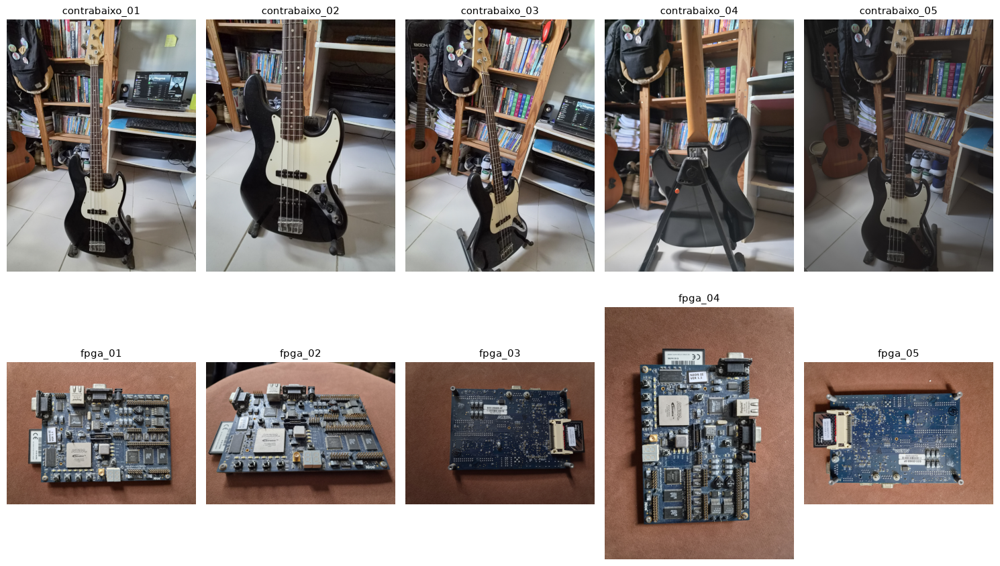

In [1]:
from pathlib import Path
import subprocess
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
from PIL import Image, ImageOps
from skimage.feature import blob_log, graycomatrix, graycoprops, local_binary_pattern
from IPython.display import display, Markdown

try:
    import google.colab
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

candidatos = [Path.cwd(), *Path.cwd().parents, Path('/content/VC_iREDE')]
RAIZ = next((p for p in candidatos if (p/'dataset/originais/fpga/fpga_01.jpg').is_file()), None)
if RAIZ is None and EM_COLAB:
    destino = Path('/content/VC_iREDE')
    if not destino.exists():
        subprocess.run(['git','clone','https://github.com/luix-felipe/VC_iREDE.git',str(destino)],check=True)
    if (destino/'dataset/originais/fpga/fpga_01.jpg').is_file():
        RAIZ = destino
if RAIZ is None:
    raise FileNotFoundError('Disponibilize dataset/originais junto ao notebook.')

TABELAS = RAIZ/'tabelas/atividade_5'
SAIDA = RAIZ/'dataset/derivadas/atividade_5'
FIGURAS = SAIDA/'figuras'
for pasta in [TABELAS, SAIDA, FIGURAS]:
    pasta.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi':100, 'font.size':10, 'axes.titlesize':11})

def ler_rgb(caminho):
    with Image.open(caminho) as arq:
        return np.array(ImageOps.exif_transpose(arq).convert('RGB'))

def cinza(rgb):
    return cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

def reduzir(rgb, maximo=1000):
    escala = min(1, maximo/max(rgb.shape[:2]))
    return cv2.resize(rgb, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA)

def histograma(a):
    contagem = np.bincount(a.ravel(), minlength=256).astype(float)
    return contagem/contagem.sum()

def estatisticas(a):
    p = histograma(a)
    p = p[p > 0]
    return {'media':float(a.mean()), 'variancia':float(a.var()),
            'desvio_padrao':float(a.std()), 'entropia_bits':float(-np.sum(p*np.log2(p)))}

def tabela(df, nomes, nome=None, casas=3):
    if nome:
        df.to_csv(TABELAS/f'{nome}.csv', index=False)
    display(df[list(nomes)].rename(columns=nomes).style.hide(axis='index')
            .format(precision=casas, na_rep='—'))

def figura(fig, nome):
    fig.tight_layout()
    fig.savefig(FIGURAS/f'{nome}.png', dpi=130, bbox_inches='tight')
    plt.show(); plt.close(fig)

CAMINHOS = {p.stem:p for p in sorted((RAIZ/'dataset/originais').glob('*/*.jpg'))}
assert len(CAMINHOS) == 10
assert all(sum(p.parent.name == c for p in CAMINHOS.values()) == 5
           for c in ['contrabaixo','fpga'])
IMAGENS = {nome:reduzir(ler_rgb(p)) for nome,p in CAMINHOS.items()}

fig, eixos = plt.subplots(2,5,figsize=(15,9))
for eixo,(nome,rgb) in zip(eixos.flat,IMAGENS.items()):
    eixo.imshow(rgb); eixo.set_title(nome); eixo.axis('off')
figura(fig,'01_dataset')

A orientação EXIF foi respeitada na leitura. As estatísticas globais abaixo usam todas
as fotos na resolução original, sem redução. Para cantos, blobs e ORB, o maior lado foi
limitado a 1.000 pixels, preservando a proporção, para reduzir o tempo de processamento.
Os arquivos originais foram preservados.

## 2. Análise global: histogramas e estatísticas

### 2.1 Estatísticas das 10 imagens

Média indica o nível médio de cinza; variância e desvio padrão mostram dispersão de
intensidades. A entropia foi calculada em bits, usando o histograma de 256 níveis.
Foi utilizada a variância populacional (`ddof=0`).

In [2]:
linhas = []
for nome,caminho in CAMINHOS.items():
    rgb = ler_rgb(caminho)
    g = cinza(rgb)
    linhas.append({'classe':caminho.parent.name, 'imagem':caminho.name, **estatisticas(g),
                   'media_r':float(rgb[:,:,0].mean()), 'media_g':float(rgb[:,:,1].mean()),
                   'media_b':float(rgb[:,:,2].mean())})
globais = pd.DataFrame(linhas)
tabela(globais, {'classe':'Classe','imagem':'Imagem','media':'Média',
    'variancia':'Variância','desvio_padrao':'Desvio padrão','entropia_bits':'Entropia (bits)'},
    'estatisticas_globais')

Classe,Imagem,Média,Variância,Desvio padrão,Entropia (bits)
contrabaixo,contrabaixo_01.jpg,111.950,4589.915,67.749,7.655
contrabaixo,contrabaixo_02.jpg,104.636,5202.008,72.125,7.572
contrabaixo,contrabaixo_03.jpg,108.773,4503.371,67.107,7.759
contrabaixo,contrabaixo_04.jpg,96.239,3644.164,60.367,7.580
contrabaixo,contrabaixo_05.jpg,68.009,1581.281,39.765,6.978
fpga,fpga_01.jpg,109.590,2367.489,48.657,7.514
fpga,fpga_02.jpg,106.491,3212.582,56.680,7.679
fpga,fpga_03.jpg,62.854,1172.603,34.243,6.809
fpga,fpga_04.jpg,104.547,2214.839,47.062,7.420
fpga,fpga_05.jpg,109.935,1824.837,42.718,7.253


As duas classes têm médias sobrepostas: por exemplo, `contrabaixo_01` e `fpga_01` estão
próximas de 112 e 110. Já as fotos com menor exposição (`contrabaixo_05` e `fpga_03`)
têm médias e entropias menores. Assim, a iluminação influenciou bastante os valores.

A média sozinha não diferenciou bem as classes. Por isso, também foram observados os
histogramas de intensidade e dos canais de cor.

### 2.2 Histogramas de intensidade e cor

Foram escolhidas as imagens 01 e 05 do contrabaixo e 01 e 03 da FPGA para incluir
variações de exposição e enquadramento. Os histogramas são normalizados: as alturas
indicam proporção de pixels, não quantidade absoluta.

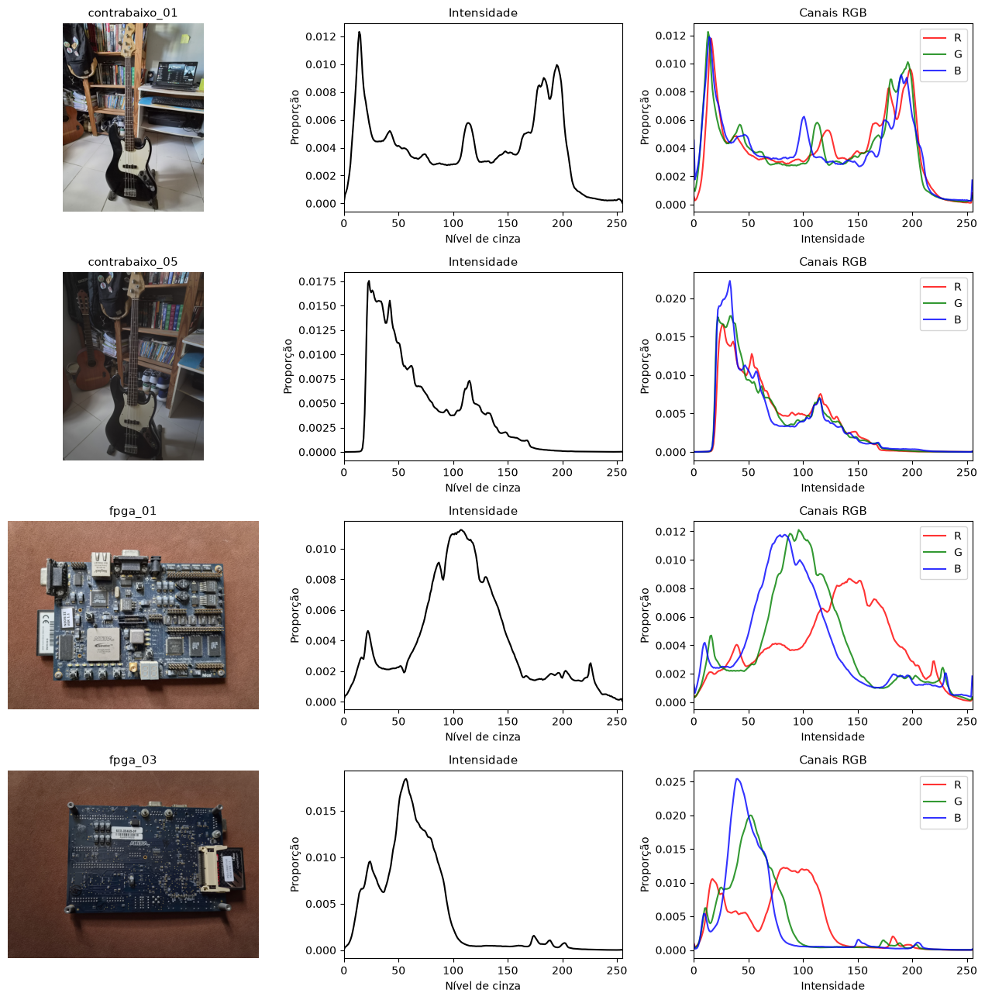

Imagem,Escuros (%),Médios (%),Claros (%)
contrabaixo_01,38.9,31.2,29.8
contrabaixo_05,69.5,29.6,0.9
fpga_01,26.9,62.2,10.9
fpga_03,83.2,13.9,2.9


Imagem,Média R,Média G,Média B
contrabaixo_01.jpg,115.3,111.2,106.8
contrabaixo_05.jpg,71.1,66.9,65.7
fpga_01.jpg,125.7,104.1,95.6
fpga_03.jpg,76.4,57.8,53.4


In [3]:
ESCOLHIDAS = ['contrabaixo_01','contrabaixo_05','fpga_01','fpga_03']
fig, eixos = plt.subplots(4,3,figsize=(13,13))
linhas = []
for linha,nome in enumerate(ESCOLHIDAS):
    rgb = ler_rgb(CAMINHOS[nome]); g = cinza(rgb); p = histograma(g)
    eixos[linha,0].imshow(reduzir(rgb)); eixos[linha,0].axis('off')
    eixos[linha,0].set_title(nome)
    eixos[linha,1].plot(np.arange(256),p,color='black')
    eixos[linha,1].set(title='Intensidade',xlabel='Nível de cinza',ylabel='Proporção',xlim=(0,255))
    for canal,cor in enumerate(['red','green','blue']):
        eixos[linha,2].plot(np.arange(256),histograma(rgb[:,:,canal]),color=cor,
                            label=['R','G','B'][canal],alpha=0.8)
    eixos[linha,2].set(title='Canais RGB',xlabel='Intensidade',ylabel='Proporção',xlim=(0,255))
    eixos[linha,2].legend()
    linhas.append({'imagem':nome, 'escuros_pct':100*p[:85].sum(),
        'medios_pct':100*p[85:171].sum(), 'claros_pct':100*p[171:].sum()})
figura(fig,'02_histogramas')
faixas = pd.DataFrame(linhas)
tabela(faixas, {'imagem':'Imagem','escuros_pct':'Escuros (%)','medios_pct':'Médios (%)',
               'claros_pct':'Claros (%)'},'faixas_intensidade',1)
tabela(globais[globais.imagem.str.removesuffix('.jpg').isin(ESCOLHIDAS)],
    {'imagem':'Imagem','media_r':'Média R','media_g':'Média G','media_b':'Média B'},casas=1)

Os grupos escuro, médio e claro foram definidos como 0–84, 85–170 e 171–255, apenas para
organizar a leitura. Na `fpga_01`, 62,2% dos pixels estão nos tons médios; na
`contrabaixo_01`, os escuros são a maior faixa, com 38,9%, mas há presença importante
de médios e claros. Nas capturas menos expostas, os escuros chegam a 69,5% no
`contrabaixo_05` e a 83,2% na `fpga_03`.
O canal vermelho tem a maior média nas quatro imagens; essa predominância é mais
acentuada na FPGA, influenciada pelo fundo marrom. O fato de a placa ser azul não implica
predomínio azul na imagem inteira.

As capturas da mesma classe compartilham alguns padrões, mas a exposição e a área
ocupada pelo fundo modificam as distribuições. Os histogramas mostraram brilho e cor,
mas não separaram claramente as classes. Eles também não mostram onde os pixels estão
na imagem, perdendo a informação de forma dos objetos.

A predominância de R na FPGA ficou mais fácil de entender ao observar o fundo marrom:
o histograma inclui a fotografia inteira, e não apenas a placa azul.

### 2.3 Comparação com derivadas da Atividade 1

Utilizei as versões PNG com largura e altura a 20% para `contrabaixo_01` e `fpga_01`.
Elas contêm 4% dos pixels originais. Os histogramas continuam com os mesmos 256 bins,
para comparar a entropia. Salvar em PNG não recupera os detalhes perdidos na redução.

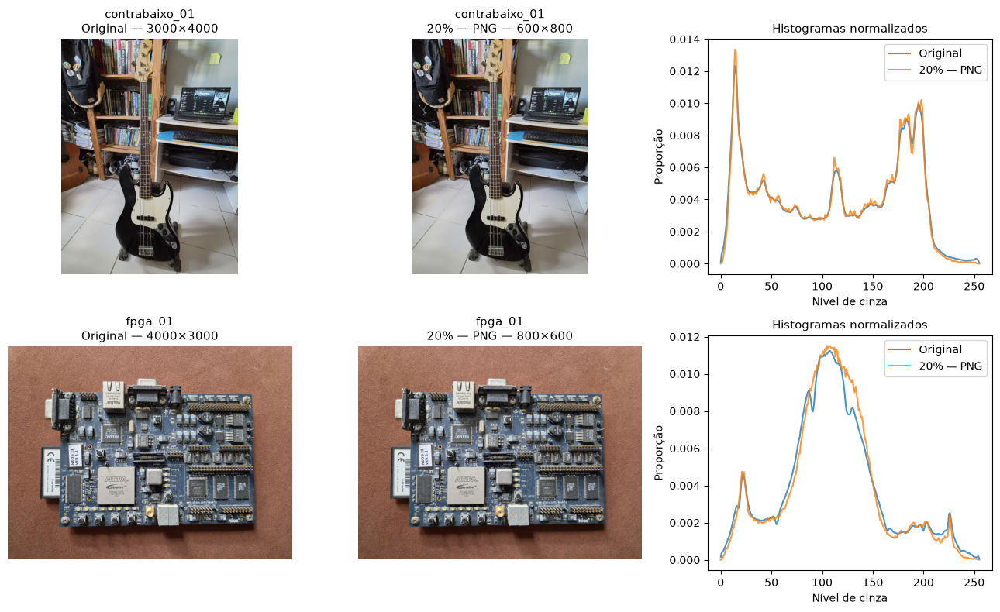

Classe,Versão,Largura,Altura,Pixels,Entropia (bits),Desvio padrão
contrabaixo,Original,3000,4000,12000000,7.655,67.749
contrabaixo,20% — PNG,600,800,480000,7.611,66.676
fpga,Original,4000,3000,12000000,7.514,48.657
fpga,20% — PNG,800,600,480000,7.414,45.635


In [4]:
linhas = []
fig, eixos = plt.subplots(2,3,figsize=(13,8))
for linha,nome in enumerate(['contrabaixo_01','fpga_01']):
    classe = CAMINHOS[nome].parent.name
    caminho_derivada = RAIZ/f'dataset/derivadas/resolucao/{classe}/{nome}_20.png'
    if not caminho_derivada.is_file():
        raise FileNotFoundError(f'Inclua a derivada da Atividade 1: {caminho_derivada}')
    original = ler_rgb(CAMINHOS[nome]); derivada = ler_rgb(caminho_derivada)
    for coluna,(versao,rgb) in enumerate([('Original',original),('20% — PNG',derivada)]):
        g = cinza(rgb); h,w = g.shape
        eixos[linha,coluna].imshow(rgb)
        eixos[linha,coluna].set_title(f'{nome}\n{versao} — {w}×{h}')
        eixos[linha,coluna].axis('off')
        eixos[linha,2].plot(np.arange(256),histograma(g),label=versao,alpha=0.8)
        linhas.append({'classe':classe,'versao':versao,'largura':w,'altura':h,
                       'pixels':h*w,**estatisticas(g)})
    eixos[linha,2].set(title='Histogramas normalizados',xlabel='Nível de cinza',ylabel='Proporção')
    eixos[linha,2].legend()
figura(fig,'03_derivadas')
derivadas = pd.DataFrame(linhas)
tabela(derivadas, {'classe':'Classe','versao':'Versão','largura':'Largura','altura':'Altura',
    'pixels':'Pixels','entropia_bits':'Entropia (bits)','desvio_padrao':'Desvio padrão'},'derivadas')

Neste experimento, a entropia caiu de 7,655 para 7,611 bits no contrabaixo e de 7,514
para 7,414 bits na FPGA. A queda foi pequena, apesar da redução de 96% dos pixels.
O formato geral dos histogramas mudou pouco, mas letras, terminais e cordas perderam
definição. Na exibição ajustada ao tamanho da tela, essa diferença pode parecer menor.

In [5]:
for classe,grupo in derivadas.groupby('classe',sort=False):
    original,menor = grupo.iloc[0],grupo.iloc[1]
    delta = menor.entropia_bits-original.entropia_bits
    display(Markdown(f'**{classe}:** entropia {original.entropia_bits:.3f} → '
        f'{menor.entropia_bits:.3f} bits (Δ={delta:+.3f}); '
        f'{100*menor.pixels/original.pixels:.0f}% dos pixels preservados.'))

**contrabaixo:** entropia 7.655 → 7.611 bits (Δ=-0.044); 4% dos pixels preservados.

**fpga:** entropia 7.514 → 7.414 bits (Δ=-0.100); 4% dos pixels preservados.

## 3. Análise local: pontos de interesse, ORB e matching

### 3.1 Cantos e blobs

Shi-Tomasi foi aplicado em uma imagem de cada classe, com até 150 cantos, qualidade
mínima relativa 0,02 e separação mínima de 10 pixels. Para blobs, usei uma imagem
adicional (`fpga_02`): LoG com σ entre 2 e 12 e dez escalas, na faixa 0–1.
Foram comparados os limiares 0,08, 0,12 e 0,18, mantendo os demais parâmetros.
O último foi usado na figura por reduzir a quantidade de marcações sobrepostas.
Os círculos têm raio aproximado √2σ. São detecções de regiões claras sobre fundo escuro,
não identificações de componentes.

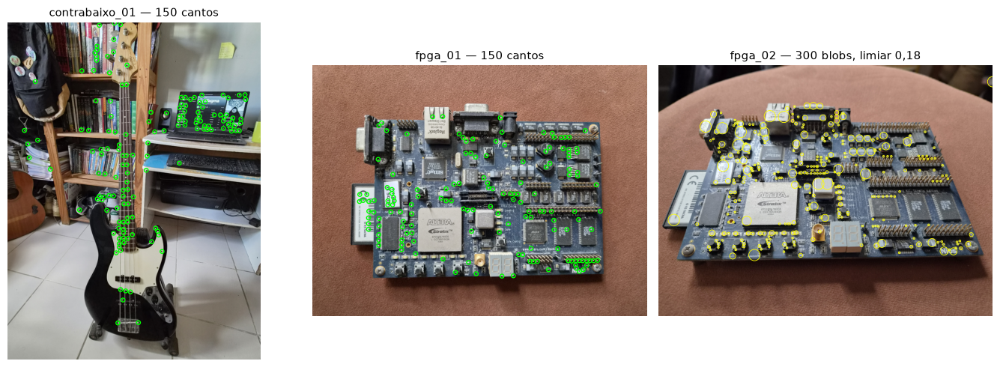

Imagem,Método,Pontos
contrabaixo_01,Shi-Tomasi,150
fpga_01,Shi-Tomasi,150
fpga_02,LoG,300


Limiar LoG,Blobs encontrados
0.08,1501
0.12,999
0.18,300


In [6]:
fig, eixos = plt.subplots(1,3,figsize=(14,5))
linhas = []
for eixo,nome in zip(eixos[:2],['contrabaixo_01','fpga_01']):
    rgb = IMAGENS[nome]; g = cinza(rgb)
    pontos = cv2.goodFeaturesToTrack(g,maxCorners=150,qualityLevel=0.02,minDistance=10,blockSize=3)
    xy = pontos.reshape(-1,2) if pontos is not None else np.empty((0,2))
    eixo.imshow(rgb)
    eixo.scatter(xy[:,0],xy[:,1],s=14,facecolors='none',edgecolors='lime')
    eixo.set_title(f'{nome} — {len(xy)} cantos'); eixo.axis('off')
    linhas.append({'imagem':nome,'metodo':'Shi-Tomasi','quantidade':len(xy)})
nome = 'fpga_02'; rgb = IMAGENS[nome]
testes_blobs = []
for limiar in [0.08,0.12,0.18]:
    blobs_teste = blob_log(cinza(rgb).astype(np.float32)/255,min_sigma=2,max_sigma=12,
                          num_sigma=10,threshold=limiar,overlap=0.5)
    testes_blobs.append({'limiar':limiar,'quantidade':len(blobs_teste)})
    if limiar == 0.18:
        blobs = blobs_teste
eixos[2].imshow(rgb)
for y,x,sigma in blobs:
    eixos[2].add_patch(Circle((x,y),np.sqrt(2)*sigma,fill=False,color='yellow',linewidth=0.6))
eixos[2].set_title(f'{nome} — {len(blobs)} blobs, limiar 0,18'); eixos[2].axis('off')
linhas.append({'imagem':nome,'metodo':'LoG','quantidade':len(blobs)})
figura(fig,'04_pontos_interesse')
tabela(pd.DataFrame(linhas),{'imagem':'Imagem','metodo':'Método','quantidade':'Pontos'},'pontos_interesse',0)
tabela(pd.DataFrame(testes_blobs),{'limiar':'Limiar LoG','quantidade':'Blobs encontrados'},
       'ajuste_blobs',2)

Os cantos aparecem em conectores, componentes, controles, cordas e também na estante.
As duas imagens atingiram o limite de 150 cantos; esse empate não prova que tenham a
mesma quantidade de detalhes. No LoG, a primeira tentativa com limiar 0,08 produziu
1.501 regiões e deixou a visualização muito carregada. Com 0,12 foram 999 e com 0,18,
300. Aumentar o limiar reduziu detecções fracas, mas não transformou o método em um
contador de componentes.

O LoG marcou detalhes claros e reflexos, mas os componentes não são todos arredondados
nem têm contraste semelhante. Por isso, as marcações não corresponderam a uma contagem
de peças. Os cantos e os descritores ORB foram mais úteis para comparar a estrutura.

### 3.2 ORB e correspondências entre pares

Usei dois pares da mesma classe, um de cada classe, e um par entre classes diferentes.
Os pares internos mostram a mesma face do objeto, para existir sobreposição visual.
ORB usa descritores binários; o BFMatcher usa distância de **Hamming**, com `WTA_K=2`.
O teste de razão mantém o melhor vizinho quando sua distância é menor que 75% da
distância do segundo. A ideia é descartar associações muito parecidas com outras opções.

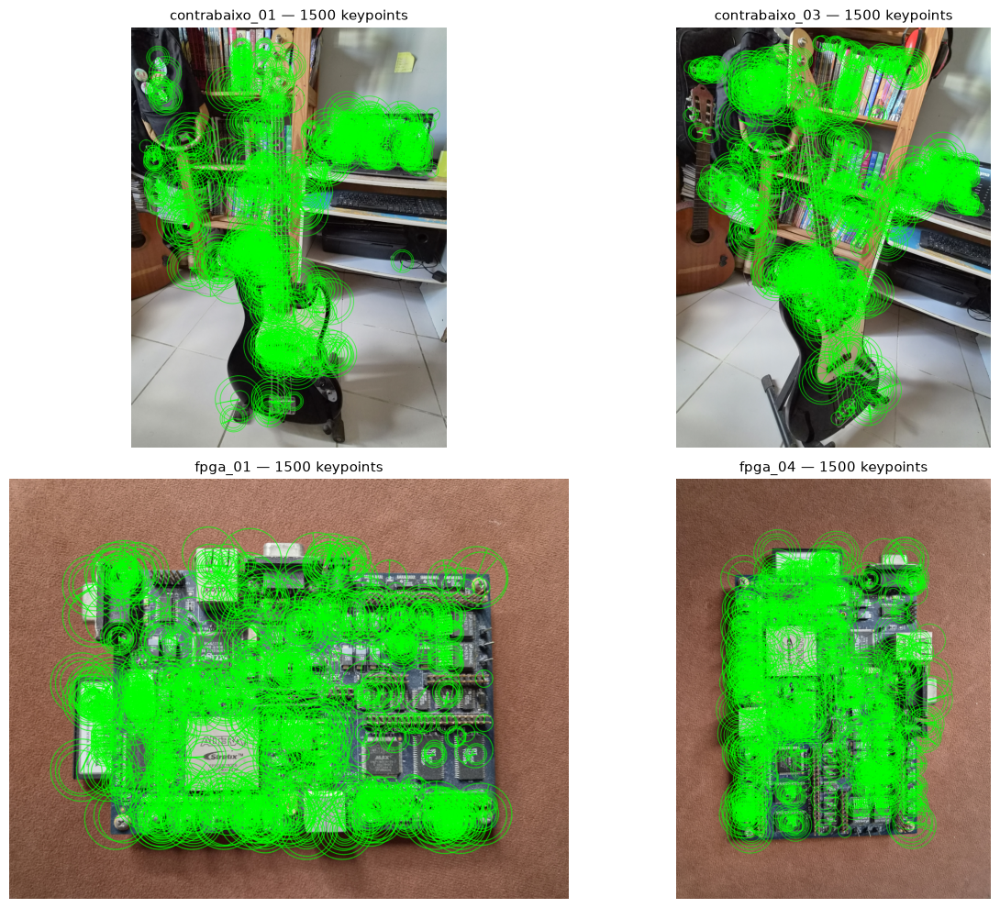

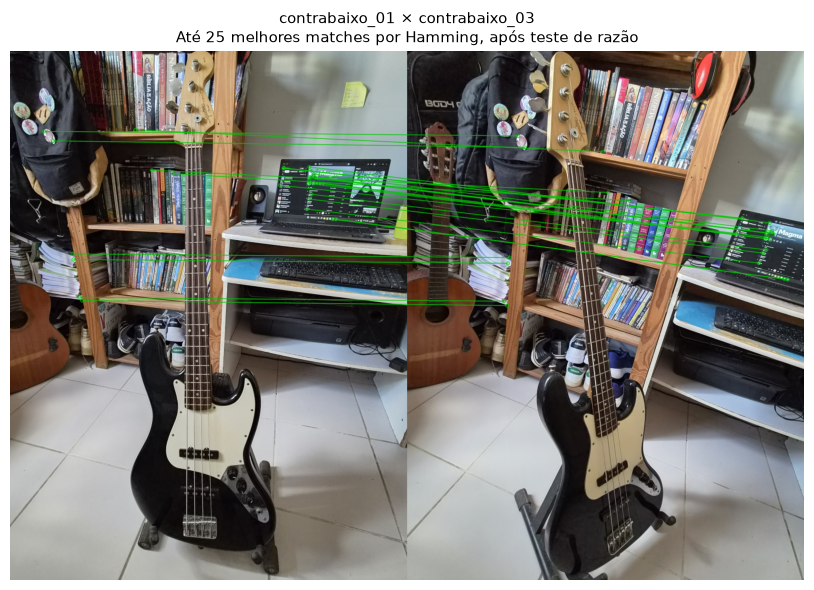

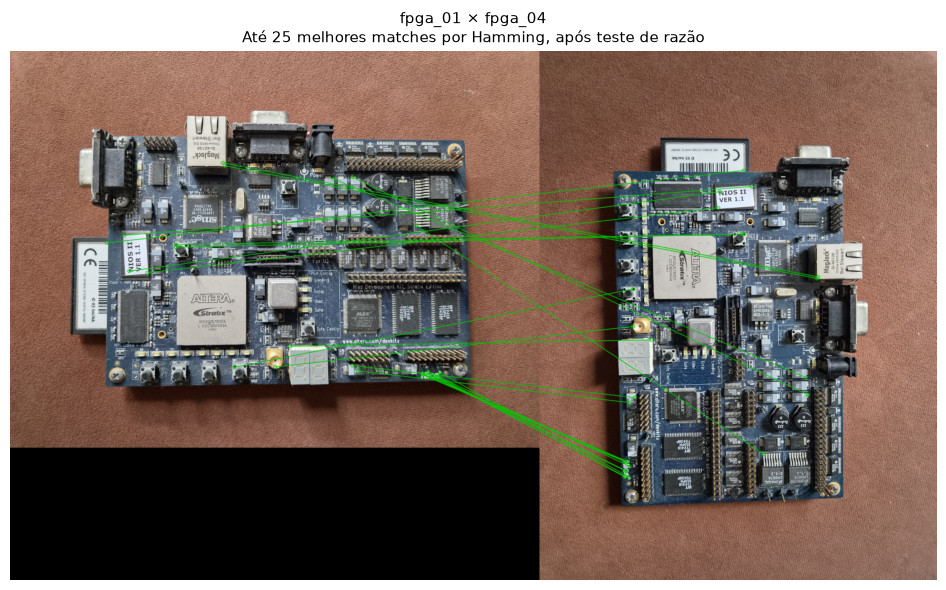

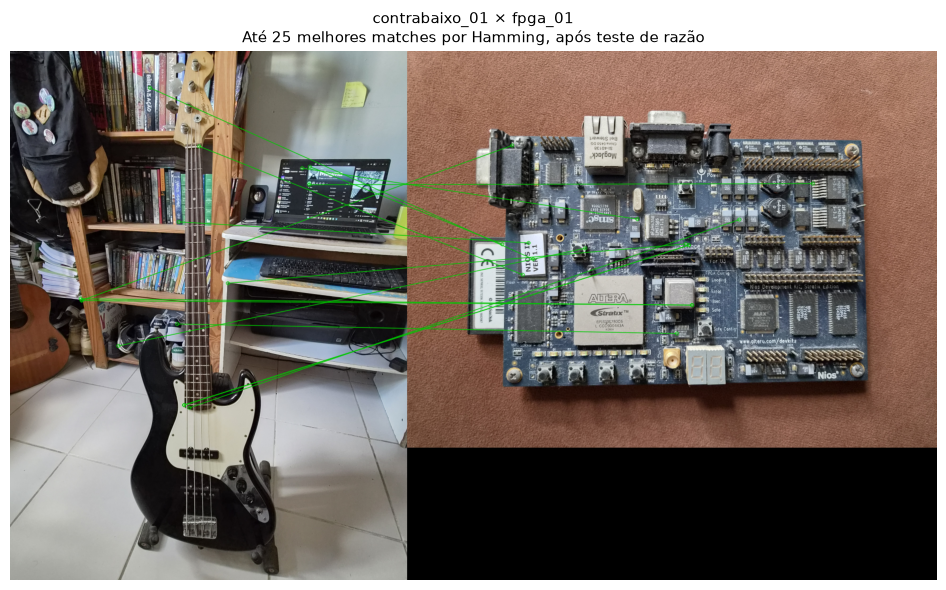

Par,Imagem A,Imagem B,Keypoints A,Keypoints B,Candidatos,Matches aceitos
Contrabaixo,contrabaixo_01,contrabaixo_03,1500,1500,1500,242
FPGA,fpga_01,fpga_04,1500,1500,1500,415
Classes diferentes,contrabaixo_01,fpga_01,1500,1500,1500,15


In [7]:
ORB = cv2.ORB_create(nfeatures=1500,scaleFactor=1.2,nlevels=8,fastThreshold=20,WTA_K=2)
FEATURES = {nome:ORB.detectAndCompute(cinza(rgb),None) for nome,rgb in IMAGENS.items()}

def comparar(descritores_a,descritores_b):
    if descritores_a is None or descritores_b is None or len(descritores_a)==0 or len(descritores_b)<2:
        return [],0
    vizinhos = cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(descritores_a,descritores_b,k=2)
    completos = [par for par in vizinhos if len(par)==2]
    bons = [m for m,n in completos if m.distance<0.75*n.distance]
    return sorted(bons,key=lambda m:m.distance),len(completos)

PARES = [('Contrabaixo','contrabaixo_01','contrabaixo_03'),
         ('FPGA','fpga_01','fpga_04'),
         ('Classes diferentes','contrabaixo_01','fpga_01')]
fig, eixos = plt.subplots(2,2,figsize=(13,10))
for eixo,nome in zip(eixos.flat,['contrabaixo_01','contrabaixo_03','fpga_01','fpga_04']):
    kp,desc = FEATURES[nome]
    marcada = cv2.drawKeypoints(IMAGENS[nome],kp,None,color=(0,255,0),
                               flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    eixo.imshow(marcada); eixo.set_title(f'{nome} — {len(kp)} keypoints'); eixo.axis('off')
figura(fig,'05_orb')

linhas = []
for indice,(tipo,a,b) in enumerate(PARES,1):
    ka,da = FEATURES[a]; kb,db = FEATURES[b]
    bons,candidatos = comparar(da,db)
    linhas.append({'par':tipo,'imagem_a':a,'imagem_b':b,'keypoints_a':len(ka),
        'keypoints_b':len(kb),'candidatos':candidatos,'aceitos':len(bons)})
    combinada = cv2.drawMatches(IMAGENS[a],ka,IMAGENS[b],kb,bons[:25],None,
        matchColor=(0,200,0),flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    fig,ax = plt.subplots(figsize=(13,6))
    ax.imshow(combinada); ax.axis('off')
    ax.set_title(f'{a} × {b}\nAté 25 melhores matches por Hamming, após teste de razão')
    figura(fig,f'06_matching_{indice}')
matching = pd.DataFrame(linhas)
tabela(matching,{'par':'Par','imagem_a':'Imagem A','imagem_b':'Imagem B',
    'keypoints_a':'Keypoints A','keypoints_b':'Keypoints B','candidatos':'Candidatos',
    'aceitos':'Matches aceitos'},'matching',0)

Antes do teste de razão, cada par tinha 1.500 consultas com dois vizinhos candidatos.
Após o filtro, foram aceitos 242 matches no contrabaixo e 415 na FPGA, contra 15 no
par entre classes. Nas figuras, várias linhas dos pares da mesma classe ligam detalhes
semelhantes dos objetos. Na FPGA, isso aparece nos componentes; no contrabaixo, há
também linhas na estante. O fundo participou do resultado.

Todas as imagens chegaram ao limite de 1.500 keypoints. Assim, a contagem de pontos
não foi suficiente para comparar a qualidade. Também foi necessário olhar as linhas
e verificar se ligavam detalhes semelhantes. Reflexos, ângulo e padrões repetidos
podem atrapalhar essas associações.

Para conferir a influência do filtro, repeti o matching com razões 0,60, 0,75 e 0,90,
sem recalcular os descritores nem mudar os pares. Um limite maior é mais permissivo.

In [8]:
linhas = []
for razao in [0.60,0.75,0.90]:
    linha = {'razao':razao}
    for tipo,a,b in PARES:
        da,db = FEATURES[a][1],FEATURES[b][1]
        vizinhos = cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(da,db,k=2)
        linha[tipo] = sum(len(par)==2 and par[0].distance<razao*par[1].distance
                          for par in vizinhos)
    linhas.append(linha)
ajuste_matching = pd.DataFrame(linhas)
tabela(ajuste_matching,{'razao':'Limite da razão','Contrabaixo':'Par do contrabaixo',
    'FPGA':'Par da FPGA','Classes diferentes':'Par entre classes'},'ajuste_matching',2)

Limite da razão,Par do contrabaixo,Par da FPGA,Par entre classes
0.60,117,173,0
0.75,242,415,15
0.90,524,796,250


Com 0,60, os pares internos ficaram com 117 e 173 matches e o par entre classes não
reteve nenhum. Com 0,90, os números subiram para 524, 796 e 250. Essa última tentativa
aceitou muito mais associações entre objetos diferentes. Mantive 0,75 considerando
a quantidade de matches e a observação das linhas. O teste mostrou que aceitar mais
matches não significa necessariamente obter associações melhores.

### 3.3 Robustez ao borramento

A partir de `fpga_01`, na resolução de trabalho, gerei um borramento Gaussiano 7×7,
σ=1,5. Comparei a referência consigo mesma como controle e com a versão borrada.
Depois, repeti ORB e matching com os mesmos parâmetros.

Teste,Keypoints de referência,Keypoints no alvo,Matches aceitos
Controle: mesma imagem,1500,1500,1500
"Borramento 7×7, σ=1,5",1500,1500,729


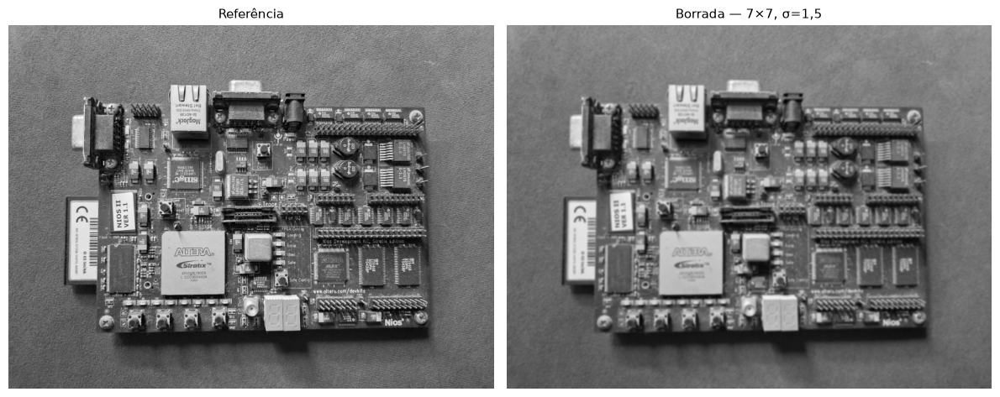

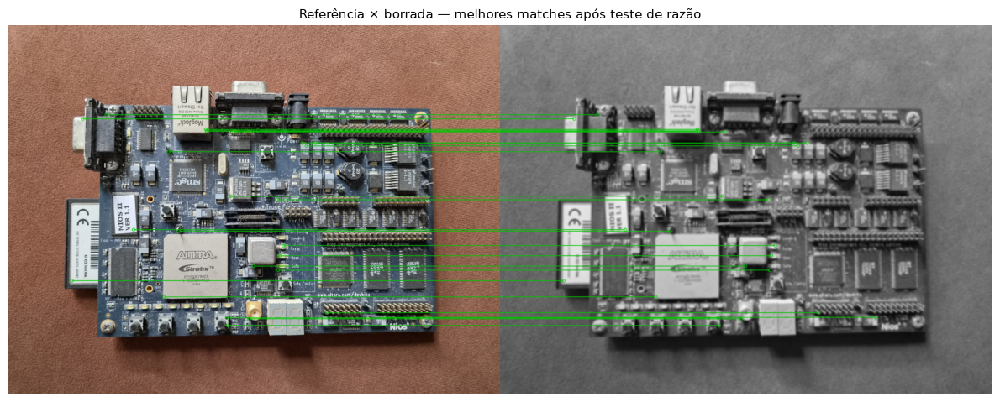

In [9]:
referencia = IMAGENS['fpga_01']; g = cinza(referencia)
borrada = cv2.GaussianBlur(g,(7,7),sigmaX=1.5,sigmaY=1.5,borderType=cv2.BORDER_REFLECT_101)
Image.fromarray(borrada).save(SAIDA/'fpga_01_borrada.png')
ka,da = FEATURES['fpga_01']
linhas = []
for nome,alvo in [('Controle: mesma imagem',g),('Borramento 7×7, σ=1,5',borrada)]:
    kb,db = ORB.detectAndCompute(alvo,None)
    bons,_ = comparar(da,db)
    linhas.append({'teste':nome,'keypoints_referencia':len(ka),'keypoints_alvo':len(kb),
        'matches':len(bons)})
    if nome.startswith('Borramento'):
        kp_borrada, matches_borrada = kb,bons
robustez = pd.DataFrame(linhas)
tabela(robustez,{'teste':'Teste','keypoints_referencia':'Keypoints de referência',
    'keypoints_alvo':'Keypoints no alvo','matches':'Matches aceitos'},'robustez',0)
fig,eixos = plt.subplots(1,2,figsize=(12,5))
for eixo,a,titulo in zip(eixos,[g,borrada],['Referência','Borrada — 7×7, σ=1,5']):
    eixo.imshow(a,cmap='gray',vmin=0,vmax=255); eixo.set_title(titulo); eixo.axis('off')
figura(fig,'07_robustez_imagens')
combinada = cv2.drawMatches(referencia,ka,cv2.cvtColor(borrada,cv2.COLOR_GRAY2RGB),
    kp_borrada,matches_borrada[:25],None,matchColor=(0,200,0),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
fig,ax = plt.subplots(figsize=(12,5)); ax.imshow(combinada); ax.axis('off')
ax.set_title('Referência × borrada — melhores matches após teste de razão')
figura(fig,'08_robustez_matching')

O número de keypoints continuou em 1.500, mas os matches caíram de 1.500 no controle
para 729 na versão borrada. Nas figuras, ainda há linhas ligando as mesmas regiões
da placa. O ORB resistiu parcialmente ao borramento, mas perdeu associações quando
os detalhes ficaram menos definidos. A contagem igual de keypoints esconde essa mudança.

## 4. Análise de textura: GLCM e LBP

### 4.1 Recortes representativos

Escolhi um recorte de 512×512 pixels dentro do corpo preto de `contrabaixo_02` e outro
na região de componentes de `fpga_01`, sem redimensioná-los. As posições centrais são
35% da largura e 74% da altura no contrabaixo e 62%/60% na FPGA, após orientação EXIF.
As caixas abaixo tornam a seleção verificável. As distâncias de captura são diferentes;
por isso, os recortes são comparados em pixels, sem medidas físicas.

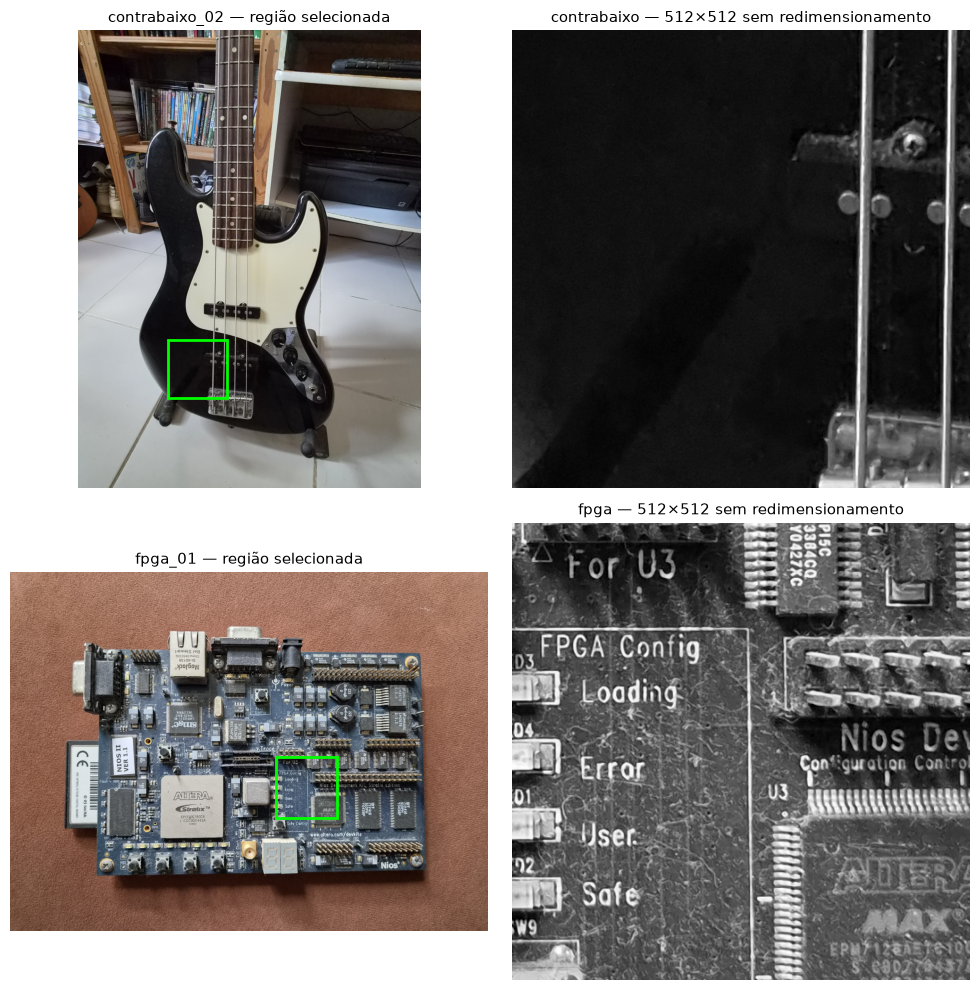

In [10]:
RECORTES = [('contrabaixo','contrabaixo_02',0.35,0.74),('fpga','fpga_01',0.62,0.60)]
PATCHES = {}
fig,eixos = plt.subplots(2,2,figsize=(10,10))
for linha,(classe,nome,cx,cy) in enumerate(RECORTES):
    rgb = ler_rgb(CAMINHOS[nome]); h,w = rgb.shape[:2]
    x0,y0 = round(cx*w)-256,round(cy*h)-256
    patch = cinza(rgb[y0:y0+512,x0:x0+512])
    assert patch.shape == (512,512)
    PATCHES[classe] = patch
    Image.fromarray(patch).save(SAIDA/f'patch_{classe}.png')
    eixos[linha,0].imshow(rgb)
    eixos[linha,0].add_patch(Rectangle((x0,y0),512,512,fill=False,edgecolor='lime',linewidth=2))
    eixos[linha,0].set_title(f'{nome} — região selecionada')
    eixos[linha,1].imshow(patch,cmap='gray',vmin=0,vmax=255)
    eixos[linha,1].set_title(f'{classe} — 512×512 sem redimensionamento')
    for eixo in eixos[linha]: eixo.axis('off')
figura(fig,'09_recortes')

O recorte da FPGA contém bordas e repetição de componentes; o do contrabaixo contém
acabamento, reflexos e parte das cordas e da ponte. Usar recortes evitou incluir a
estante e o estofado nessa etapa. Os valores descrevem essas regiões selecionadas.

### 4.2 GLCM

Quantizei o cinza em 16 níveis com `q = cinza // 16`. A GLCM foi calculada para distância
1 e ângulos 0° e 90°, simétrica e normalizada. Extraí contraste, homogeneidade, energia
e correlação usando `graycoprops`.

In [11]:
linhas = []
for classe,patch in PATCHES.items():
    quantizada = (patch//16).astype(np.uint8)
    glcm = graycomatrix(quantizada,distances=[1],angles=[0,np.pi/2],levels=16,
                       symmetric=True,normed=True)
    propriedades = {p:graycoprops(glcm,p)[0] for p in ['contrast','homogeneity','energy','correlation']}
    for indice,angulo in enumerate([0,90]):
        linhas.append({'classe':classe,'angulo_graus':angulo,
                       **{p:float(v[indice]) for p,v in propriedades.items()}})
textura = pd.DataFrame(linhas)
tabela(textura,{'classe':'Classe','angulo_graus':'Ângulo (°)','contrast':'Contraste',
    'homogeneity':'Homogeneidade','energy':'Energia','correlation':'Correlação'},'glcm',4)
for classe,grupo in textura.groupby('classe',sort=False):
    display(Markdown(f'**{classe}:** contraste médio {grupo.contrast.mean():.4f}; '
        f'homogeneidade média {grupo.homogeneity.mean():.4f}; '
        f'energia média {grupo.energy.mean():.4f}.'))

Classe,Ângulo (°),Contraste,Homogeneidade,Energia,Correlação
contrabaixo,0,0.5679,0.8837,0.5242,0.9459
contrabaixo,90,0.1978,0.9100,0.5278,0.9810
fpga,0,1.7310,0.6964,0.1991,0.9201
fpga,90,1.8597,0.6875,0.1977,0.9143


**contrabaixo:** contraste médio 0.3828; homogeneidade média 0.8969; energia média 0.5260.

**fpga:** contraste médio 1.7954; homogeneidade média 0.6920; energia média 0.1984.

O contraste mostra diferenças de intensidade entre vizinhos; a homogeneidade é maior
quando eles têm valores próximos. A energia indica concentração em poucos pares, e a
correlação mostra a relação entre as intensidades vizinhas.

Na FPGA, o contraste médio entre os dois ângulos foi 1,795, contra 0,383 no contrabaixo;
a homogeneidade média foi menor, 0,692 contra 0,897. Isso combina com as transições
de componentes e inscrições da placa. A energia também foi menor na FPGA, indicando
pares de intensidades mais distribuídos. No contrabaixo, o contraste horizontal foi
maior que o vertical, compatível com as cordas e a ponte presentes no recorte.

A correlação foi alta nas duas classes: aproximadamente 0,946–0,981 no contrabaixo e
0,914–0,920 na FPGA. A mudança entre os ângulos mostra que a direção também influencia
a descrição da textura.

### 4.3 LBP

Usei LBP uniforme com 8 vizinhos e raio 1. O histograma tem 10 categorias: códigos
uniformes 0–8 e uma categoria para os não uniformes. Excluí a borda de 1 pixel do
histograma para evitar incluir vizinhanças incompletas. As duas classes usam a mesma
escala de cores e a mesma escala vertical nos histogramas.

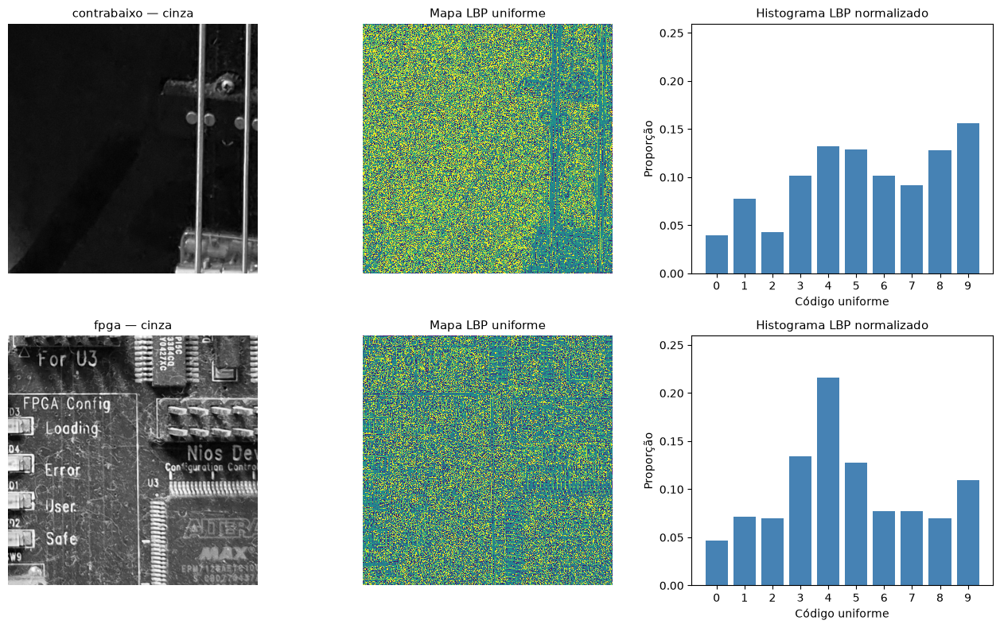

Categoria LBP,Contrabaixo (%),FPGA (%)
0,4.00,4.63
1,7.78,7.15
2,4.26,6.98
3,10.14,13.45
4,13.24,21.63
5,12.86,12.79
6,10.17,7.76
7,9.13,7.73
8,12.80,6.99
9,15.61,10.91


In [12]:
linhas = []
fig,eixos = plt.subplots(2,3,figsize=(13,8))
for linha,(classe,patch) in enumerate(PATCHES.items()):
    mapa = local_binary_pattern(patch,P=8,R=1,method='uniform')
    hist,_ = np.histogram(mapa[1:-1,1:-1],bins=np.arange(11),range=(0,10))
    hist = hist/hist.sum()
    linhas.extend({'classe':classe,'padrao':i,'proporcao':float(p)} for i,p in enumerate(hist))
    eixos[linha,0].imshow(patch,cmap='gray',vmin=0,vmax=255)
    eixos[linha,0].set_title(f'{classe} — cinza'); eixos[linha,0].axis('off')
    eixos[linha,1].imshow(mapa,cmap='viridis',vmin=0,vmax=9,interpolation='nearest')
    eixos[linha,1].set_title('Mapa LBP uniforme'); eixos[linha,1].axis('off')
    eixos[linha,2].bar(np.arange(10),hist,color='steelblue')
    eixos[linha,2].set(title='Histograma LBP normalizado',xlabel='Código uniforme',ylabel='Proporção',
                      xticks=range(10))
lbp_histogramas = pd.DataFrame(linhas)
limite_lbp = min(1,1.2*lbp_histogramas.proporcao.max())
for eixo in eixos[:,2]:
    eixo.set_ylim(0,limite_lbp)
figura(fig,'10_lbp')
lbp_histogramas.to_csv(TABELAS/'lbp.csv',index=False)
comparacao_lbp = (100*lbp_histogramas.pivot(index='padrao',columns='classe',values='proporcao')).reset_index()
tabela(comparacao_lbp,{'padrao':'Categoria LBP','contrabaixo':'Contrabaixo (%)',
                      'fpga':'FPGA (%)'},casas=2)

A FPGA teve maior concentração na categoria LBP 4 (21,6%, contra 13,2% no contrabaixo),
compatível com padrões de borda. Os padrões não uniformes foram 10,9% na FPGA e 15,6%
no contrabaixo, onde reflexos e pequenas variações também aparecem. O LBP registrou
detalhes mesmo na região de acabamento aparentemente liso.

Os histogramas LBP e a GLCM mostraram diferenças entre os recortes: a FPGA teve maior
contraste, enquanto o contrabaixo foi mais homogêneo. Eles ajudaram a comparar textura,
mas um recorte de cada classe ainda é pouco para avaliar o conjunto inteiro. Ambos
perdem a forma geral dos objetos e dependem da região escolhida.

## 5. Síntese integradora

A tabela reúne o que cada representação preservou, o que perdeu e sua contribuição
na comparação das imagens.

In [13]:
sintese = pd.DataFrame([
    ['Histogramas','Distribuição de intensidades e cores','Simples e normalizáveis',
     'Perdem posição; fundo e exposição influenciam','Pistas de cor, sem separação confiável'],
    ['Estatística global','Brilho, dispersão e entropia','Resume a aquisição com poucos números',
     'Imagens diferentes podem ter médias próximas','Útil para exposição; média pouco útil para separar classes'],
    ['ORB + matching','Aparência e estrutura de vizinhanças','Reencontra detalhes em vistas sobrepostas',
     'Fundo, reflexos e padrões repetidos causam ambiguidades','Mais útil para correspondência neste conjunto'],
    ['GLCM','Relações entre intensidades vizinhas','Mede contraste e direcionalidade',
     'Depende do recorte, direção e quantização','Diferenciou os recortes, mas não descreve o objeto inteiro'],
    ['LBP','Padrões locais relativos ao centro','Histograma compacto de microestruturas',
     'Perde a forma geral e depende do recorte','Mostrou diferenças locais de textura']
],columns=['descritor','representa','vantagens','limitacoes','resultado'])
tabela(sintese,{'descritor':'Tipo de descritor','representa':'O que representa','vantagens':'Vantagens',
    'limitacoes':'Limitações','resultado':'Funcionou bem no meu dataset?'},'sintese')

Tipo de descritor,O que representa,Vantagens,Limitações,Funcionou bem no meu dataset?
Histogramas,Distribuição de intensidades e cores,Simples e normalizáveis,Perdem posição; fundo e exposição influenciam,"Pistas de cor, sem separação confiável"
Estatística global,"Brilho, dispersão e entropia",Resume a aquisição com poucos números,Imagens diferentes podem ter médias próximas,Útil para exposição; média pouco útil para separar classes
ORB + matching,Aparência e estrutura de vizinhanças,Reencontra detalhes em vistas sobrepostas,"Fundo, reflexos e padrões repetidos causam ambiguidades",Mais útil para correspondência neste conjunto
GLCM,Relações entre intensidades vizinhas,Mede contraste e direcionalidade,"Depende do recorte, direção e quantização","Diferenciou os recortes, mas não descreve o objeto inteiro"
LBP,Padrões locais relativos ao centro,Histograma compacto de microestruturas,Perde a forma geral e depende do recorte,Mostrou diferenças locais de textura


## 6. Análise dos resultados

Os resultados mostraram que cada descritor ajudou em um aspecto. Histogramas e
estatísticas evidenciaram a exposição, ORB relacionou detalhes entre as fotos e GLCM/LBP
mostraram diferenças de textura. A hipótese sobre o ORB foi a que mais se confirmou
na comparação visual dos pares.

O fundo foi uma dificuldade importante: apareceu tanto na cor predominante da FPGA
quanto nos pontos encontrados na estante. A distância, o ângulo e o enquadramento
também mudaram o tamanho e a aparência dos detalhes. Por isso, foi necessário comparar
as figuras junto com as tabelas, principalmente no matching.

No borramento, a quantidade de pontos permaneceu igual, mas as associações diminuíram.
Na redução de resolução, os histogramas ficaram parecidos, mas detalhes finos perderam
definição. Esses dois testes mostraram que um resumo numérico não descreve toda a mudança
visual. Na comparação com PNG, a imagem também foi reduzida; o efeito do formato não
foi testado separadamente.

## 7. Conclusão

O ORB com matching foi o mais útil neste dataset, pois ajudou a encontrar detalhes
semelhantes entre as fotos da mesma classe. Os pares do contrabaixo e da FPGA tiveram
242 e 415 matches aceitos, contra 15 entre classes diferentes. A média de intensidade
foi a medida menos útil para diferenciá-las, porque apresentou valores próximos.

A iluminação e o fundo influenciaram bastante os resultados. Fotos mais escuras mudaram
os histogramas, e elementos do ambiente apareceram nos pontos de interesse. O borramento
e a redução de resolução também dificultaram a observação de detalhes pequenos.

GLCM e LBP ajudaram a comparar as texturas, mas foram calculados em apenas um recorte
por classe. Para começar um sistema simples, eu usaria ORB para comparar detalhes e
histogramas de cor como complemento, procurando limitar a análise à região do objeto.
Depois, testaria mais imagens para verificar se essa escolha continua funcionando.

### Referências

- Enunciado da Atividade 5, Unidade 3, Capítulo 2 — Prof. Rafael Carmo.
- [OpenCV — Shi-Tomasi](https://docs.opencv.org/4.x/d4/d8c/tutorial_py_shi_tomasi.html).
- [OpenCV — ORB](https://docs.opencv.org/4.x/d1/d89/tutorial_py_orb.html).
- [OpenCV — BFMatcher e distância de Hamming](https://docs.opencv.org/4.x/dc/dc3/tutorial_py_matcher.html).
- [Scikit-image — blobs, GLCM, propriedades e LBP](https://scikit-image.org/docs/stable/api/skimage.feature.html).